# Real event-camera log-radiance reconstruction

## 1. Problem


We reconstruct a static indoor scene at the final time of a real16.519ms rotational event window. The27643events are indirect brightness-change measurements. An independent IMU and matching camera calibration supply motion; no gray-image-derived optical flow is input. The result is a **relative log-radiance image**, not an absolutely calibrated photograph.

For event polarity p=±1and unknown positive contrast C, ΔL=pC. Camera rotation gives velocity v(ω,K),and displacement d=vΔt. Normalize time as τ=(t−t0)/Δt,warp events by(1−τ)d,and bilinearly accumulate a signed count image H. The normalized event constraint is b=H/|d|≈Dℓ,where Dℓ(x)=ℓ(x)−ℓ(x+û),û=d/|d|. The boundary ring has zero measurement equations. Sparse events and gradients perpendicular to û leave ambiguities.

The selected original classical method solves a directional inverse problem using anisotropic TV and split Bregman. The source parameter λ=.1corresponds to objective½||Aℓ−b||²+λ²(||Gyℓ||₁+||Gxℓ||₁),with centered gradient stencils. Each outer iteration has five10-stepLSQRcorrection solves and soft thresholding; at most20outer updates are computed. A separate source-faithful Laplacian quadratic reconstruction is retained as a comparison. Images use the source's clipped1st/99th-percentile gauge.

The **qualified original oracle** explicitly corrects three source issues: seconds versus whole-window displacement, the camera matrix after undistortion,and two-dimensional flow lookup for fractional event positions. The unmodified source runs are archived separately. The timing-only control below retains corrected spatial lookup so it isolates the clock issue. Learned denoiser methods are outside the selected classical-method scope; no missing neural result is replaced with a zero image.

## 2. Data

These are real DAVIS240C measurements from an indoor boxes scene, with acquisition-only camera rectification. Native event timing and polarity are preserved; floating positions result from independent lens calibration. No complete intensity image or optical flow inferred from an intensity target is supplied.

| Key | Shape | Dtype | Description |
|---|---|---|---|
| events | (1, 27643, 4) | float64 | Rows are [time in s, x in pixel, y in pixel, polarity0/1 dimensionless]; chronological order;0 maps to−1 and1 to+1. |
| angular_velocity | (1, 3) | float64 | Independent IMU gyro [ωx,ωy,ωz], rad/s, in the camera frame. |
| intrinsics | (1, 3, 3) | float64 | Rectified pinhole matrix K; focal lengths and principal-point entries in pixels, homogeneous last row dimensionless. |

**Acquisition metadata**

| Parameter | Value | Unit | Meaning |
|---|---|---|---|
| Sensor height, width | 180,240 | pixel | Camera array, y downward and x rightward; coordinate origin is upper left. |
| Event start | 19.500000000 | s | Time in the source recording. |
| Last event minus first event | 0.016518998999998757 | s | Actual stored acquisition duration; compute it from the event timestamps. |
| Raw acquisition selection | First30000events at or after19.5s | events | Rectification and calibrated sensor-interior selection retain27643events. |
| Rectified focal lengths | 169.50404059859204,179.58096603591352 | pixel | fx,fy, matching the supplied rectified event positions. |
| Rectified principal point | 136.0468660434908,114.28206073946285 | pixel | cx,cy; also stored in K. |
| Gyro sampling convention | First IMU record at or after the median retained event time | dimensionless convention | Provides the independent short-window constant angular velocity. |
| Camera-frame gyro axes | x right,y down,z forward | dimensionless orientation | Right-handed camera coordinates and the velocity signs specified above. |
| Grid precision convention | float32 grid, focal lengths and principal point; float64 gyro/time | dimensionless convention | Preserves the original camera-flow arithmetic while retaining stored input precision. |
| Event flow lookup | floor y and floor x separately, then row-major flatten | dimensionless convention | Two-dimensional lower-neighbor sampling; warped positions remain fractional. |
| Warp boundary | Discard interpolation weights outside the sensor | dimensionless convention | Bilinear weights inside the sensor are retained without renormalization. |
| Directional-model boundary | Unit-flow and b zero on the outermost row/column | dimensionless convention | No edge observation equations; image comparison still includes every pixel. |
| Event contrast | Unknown positive, common scale | relative log-radiance unit | Removed by the declared output convention; no absolute brightness claim. |
| Data license | CC BY-NC-SA3.0 | license identifier | Attributed noncommercial research data, with acquisition-only derivative changes described in NOTICE. |

## 3. Physics

An event $(x,t,p)$ records a signed threshold crossing $\Delta L=pC$ of log radiance $L$, with polarity $p\in\{-1,1\}$ and unknown positive contrast $C$. Calibrated rotational flow gives full-window displacement $d=v\Delta t$ in pixels. Warp each event to final time by $(1-\tau)d$, $\tau=(t-t_0)/\Delta t$, and bilinearly accumulate signed events $H$. The normalized constraint is

$$
b=H/|d|\approx A\ell,\qquad (A\ell)(x)=\ell(x)-\ell(x+\hat d),\quad\hat d=d/|d|.
$$

$\ell$ is relative log radiance in unit-contrast coordinates; $A$ uses the calibrated spatial lookup. DC and contrast remain ambiguous, and directional differentiation is insensitive to some image structure.

## 4. Method

### Active bound reconstruction and independent evaluation

The following cell actively computes every method and sensitivity result from the public observations using local NumPy/SciPy code. Independent original arrays are used only for comparisons. They are **method references, not physical truth**. The output is scored on every pixel, without image alignment. The observation check allows only positive sensor-contrast scale; it does not fit the image to the reference.

The selected TV inverse minimizes $\tfrac12\|A\ell-b\|_2^2+\lambda^2(\|G_y\ell\|_1+\|G_x\ell\|_1)$, where $G_y,G_x$ are centered spatial gradients and $\lambda=0.1$. Split Bregman alternates LSQR correction solves and soft thresholding. The source-faithful quadratic inverse and clock control are separate comparisons. Percentile clipping fixes the submission gauge but changes directional residuals, so unnormalized and submitted-image diagnostics are reported separately.

## 5. Results




In [1]:
%matplotlib inline
import os,sys,time,json,subprocess
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
ROOT=Path.cwd()
if not (ROOT/'src').is_dir(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from src.preprocessing import load_observations
from src.visualization import run_experiments,make_figures,metrics
events,angular_velocity,intrinsics=load_observations(ROOT/'data/raw_data.npz')
print('Real events:',events.shape,'duration(s):',events[-1,0]-events[0,0])
print('Independent gyro (rad/s):',angular_velocity)


Real events: (27643, 4) duration(s): 0.016518998999998757
Independent gyro (rad/s): [ 0.9054747  -0.43569312  0.29720878]


In [2]:
result=run_experiments(events,angular_velocity,intrinsics)
with np.load(ROOT/'notebooks/reference_outputs/upstream_methods.npz',allow_pickle=False) as z:
    references={k:z[k].copy() for k in ['TV','Laplacian','seconds_api']}
for name in references:
    np.testing.assert_allclose(result['images'][name],references[name],rtol=0,atol=2e-7)
(ROOT/'output').mkdir(exist_ok=True)
np.savez_compressed(ROOT/'output/reconstruction.npz',reconstruction=result['images']['TV'][None])
command=[sys.executable,str(ROOT/'evaluation/judge.py'),'--prediction',str(ROOT/'output/reconstruction.npz'),'--report',str(ROOT/'output/judge_report.json')]
judged=subprocess.run(command,capture_output=True,text=True)
assert judged.returncode==0,(judged.stdout,judged.stderr)
report=json.loads((ROOT/'output/judge_report.json').read_text(encoding='utf8'))
print('Active experiment time:',result['seconds'],'seconds')
print(json.dumps(report,indent=2))


Active experiment time: 17.472529699996812 seconds
{
  "status": "pass",
  "passed": true,
  "metrics": {
    "ncc": 0.9999999999999999,
    "nrmse": 1.2389092925818223e-16,
    "observation_residual": 0.1425431451849308
  },
  "thresholds": {
    "ncc": {
      "comparison": ">=",
      "boundary": 0.999999
    },
    "nrmse": {
      "comparison": "<=",
      "boundary": 1e-06
    },
    "observation_residual": {
      "comparison": "<=",
      "boundary": 0.1496703024441773
    }
  },
  "errors": []
}


### Scientific comparisons

Five figure groups show: measured positive/negative events and independent motion; qualified-original versus freshTV/Laplacian maps; forward directional constraints and measured residuals; actual optimization history and regularization changes; and timing/motion sensitivity. Signed-event panels use the99th absolute percentile for display contrast only. All numeric metrics and evaluator inputs use complete arrays. Pixel coordinates refer to the calibrated sensor, and gyro arrows represent full-window displacement in pixels. Error maps show numerical reproduction error, not physical reconstruction error.

Figure3 evaluates the unnormalized unit-contrast log image: its relative directional residual is about0.0824. The standalone Judge evaluates the required percentile-normalized and clipped submission, with only a positive contrast-scale fit: its residual is about0.142543. These use different images and gauges; clipping changes their directional gradients. They are separately labeled diagnostics, not inconsistent reports of one metric.


{
  "TV": {
    "ncc": 0.9999999999999999,
    "nrmse": 1.2389092925818223e-16
  },
  "Laplacian": {
    "ncc": 1.0000000000000002,
    "nrmse": 1.1570173544207944e-12
  }
}


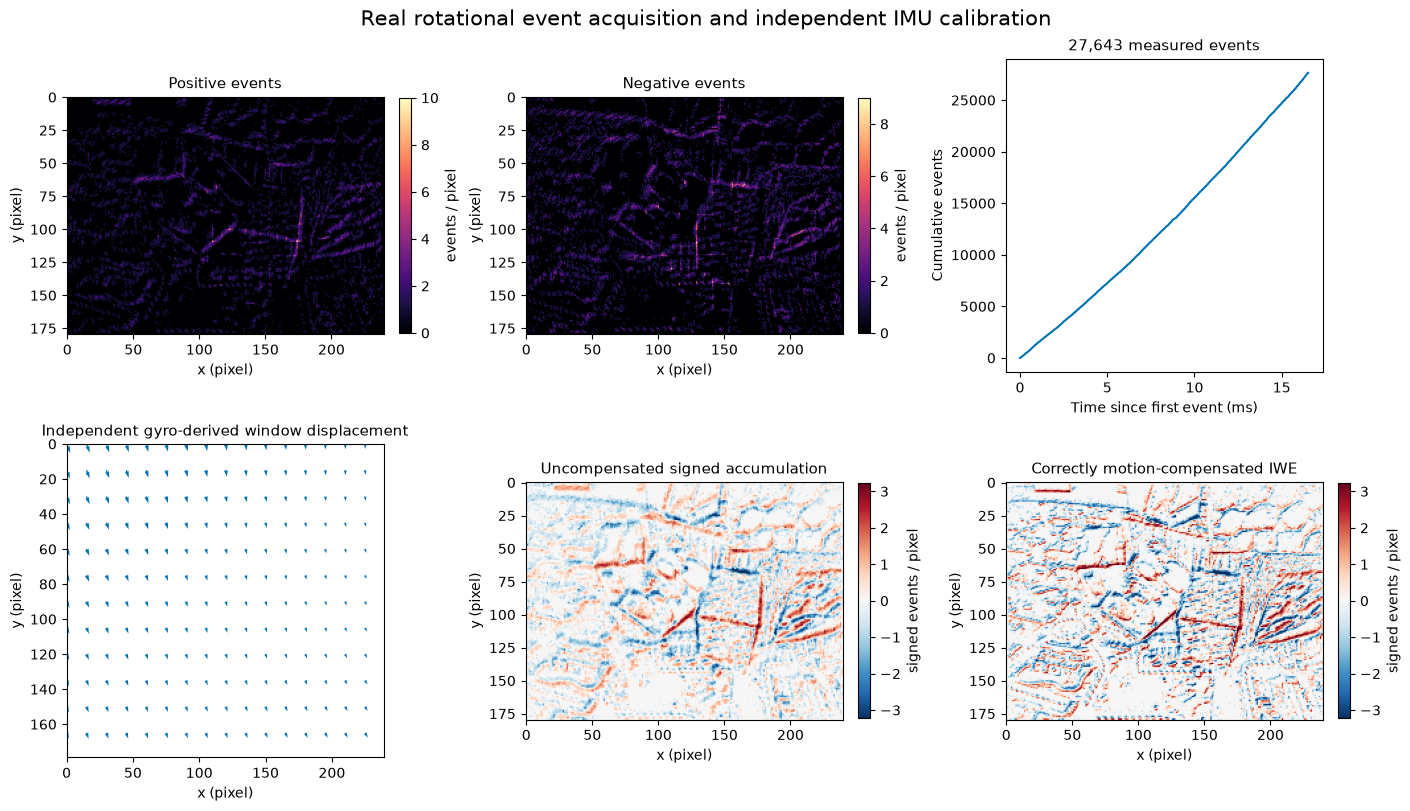

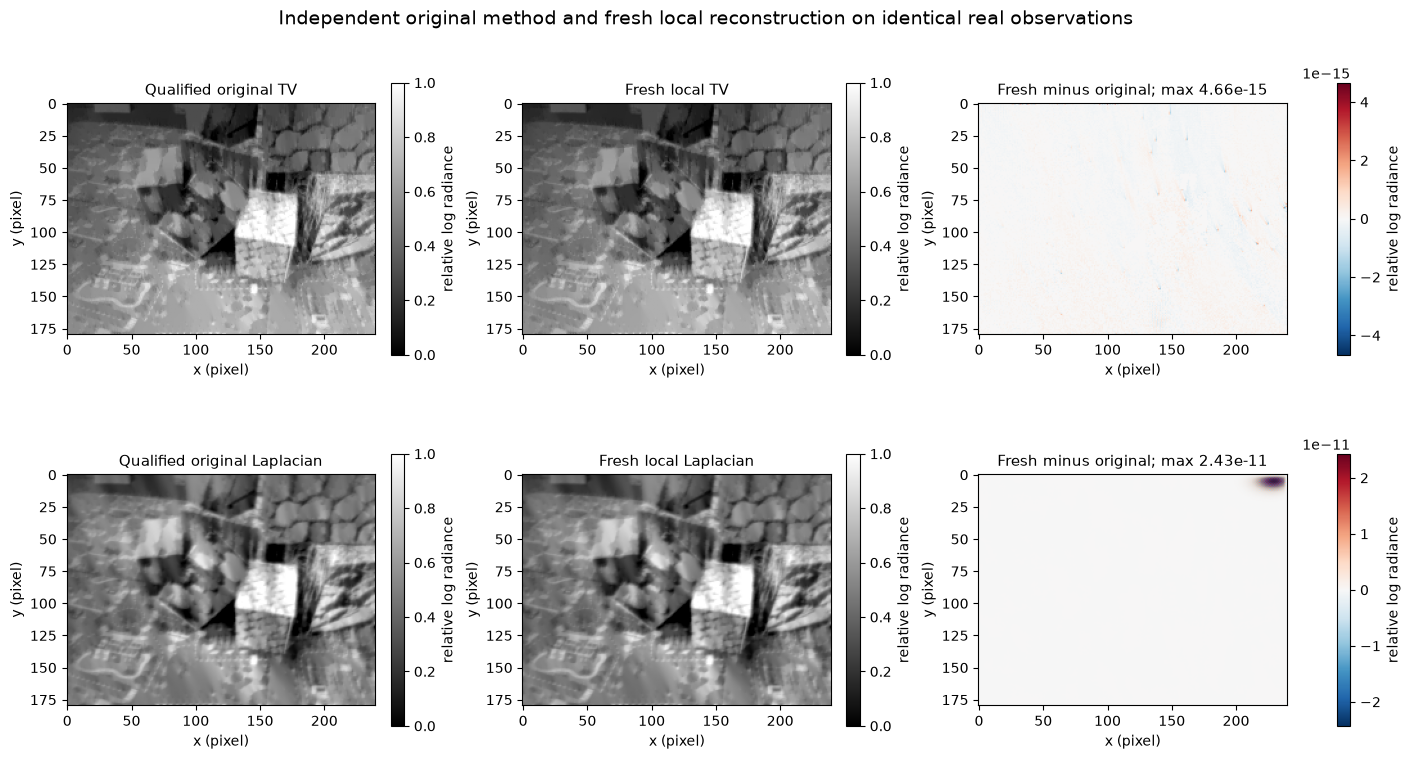

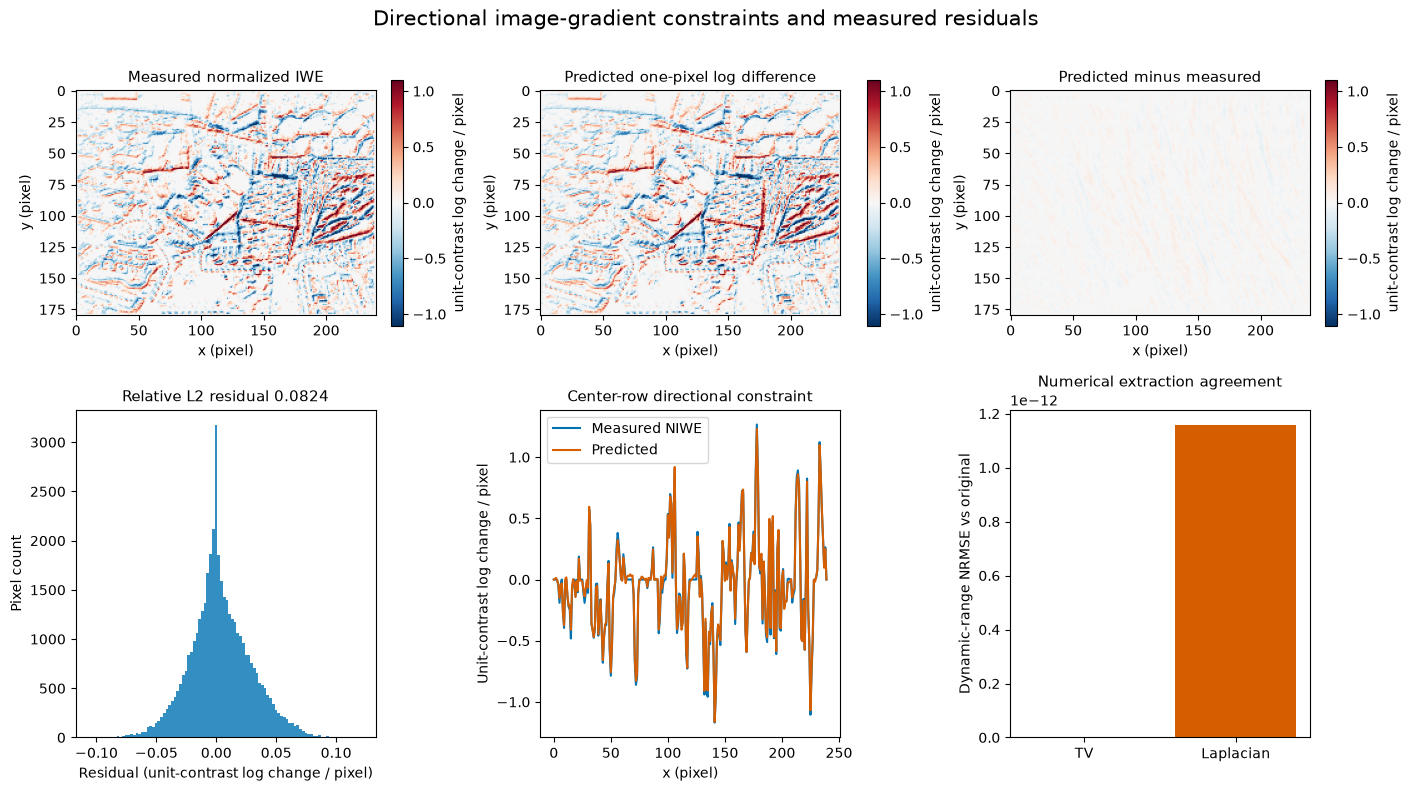

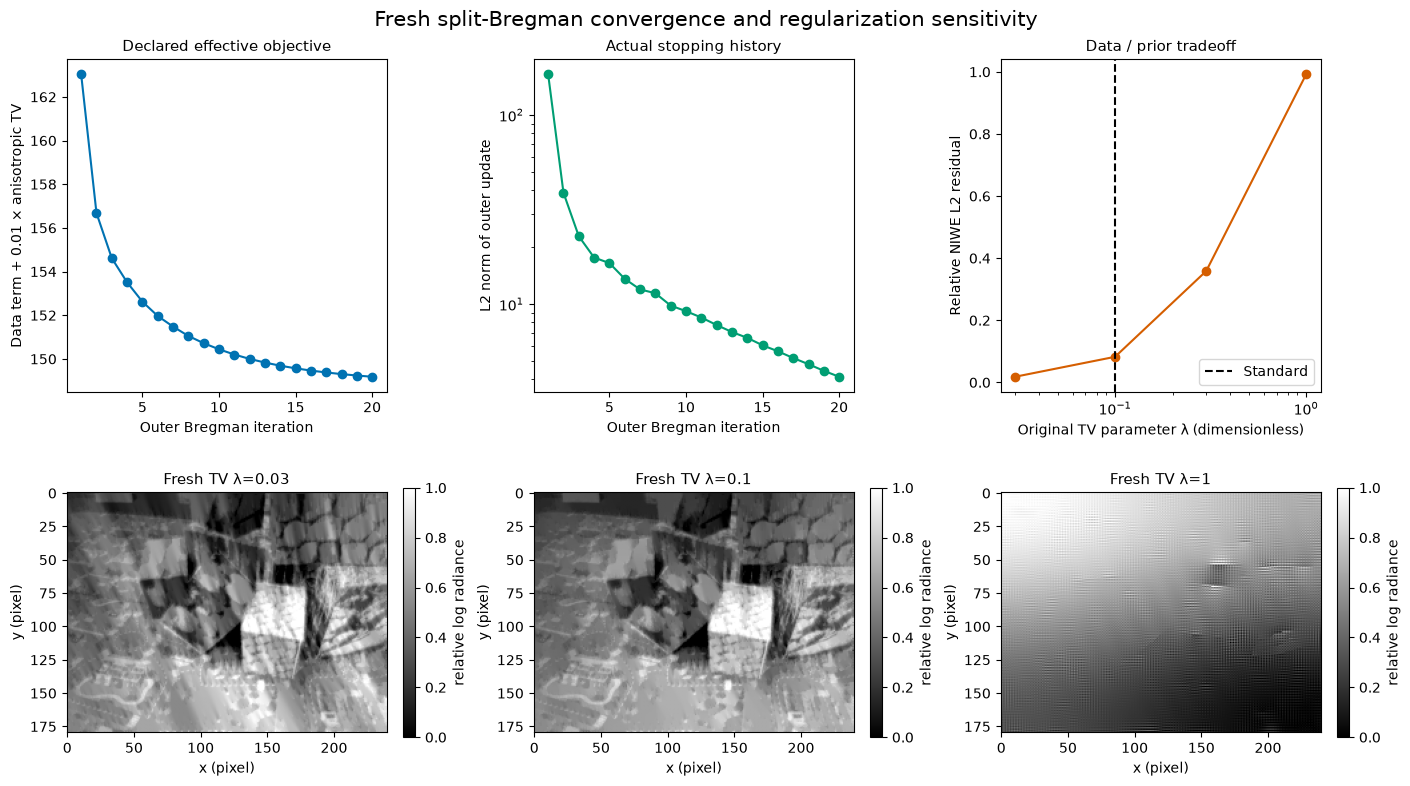

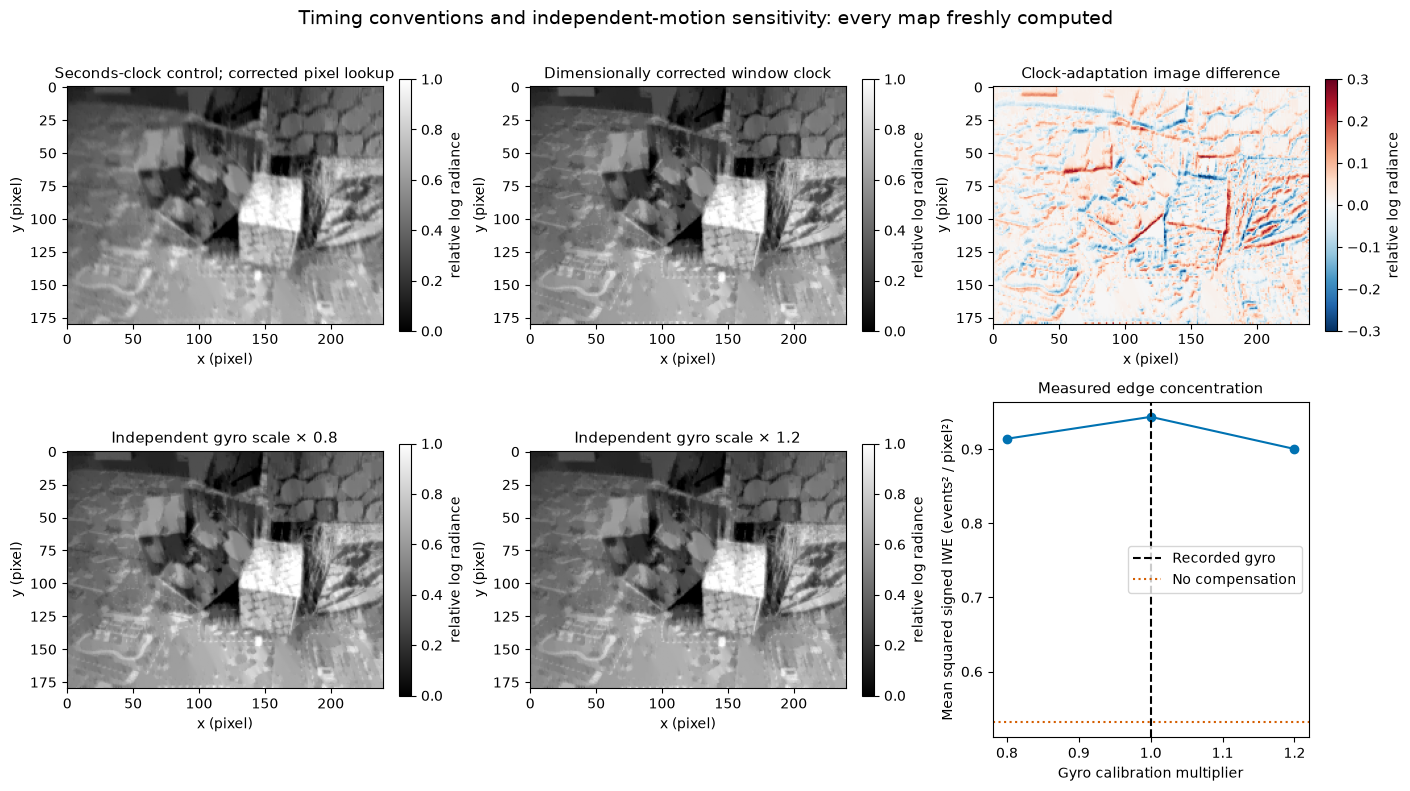

In [3]:
figures,parity_table=make_figures(result,references,os.environ.get('IMAGING_FIGURE_DIR'))
print(json.dumps(parity_table,indent=2))
for name,figure in figures:
    display(figure)
    plt.close(figure)


## 6. Conclusion

### Conclusions and limits

The fresh local reconstruction agrees with its independently executed qualified classical reference and passes the independent public-observation check. The actual edge concentration and residual measurements support the short-window motion model; equality to the reference alone would not do so. The quadratic andTVcomparisons expose prior-dependent differences, and every sensitivity map is actively reconstructed.

Brightness scale/DC, clipping, event noise, the approximate constant rotational flow and unobserved directional gradients remain limitations. No independently calibrated radiometric ground truth is available. The earlier source seconds-clock convention and the corrected result are both visible; the corrected implementation is not described as an unchanged reproduction of that convention. Data derive from the attributed CC BY-NC-SA3.0Event-Camera Dataset; the local code retains the original MITnotice.
